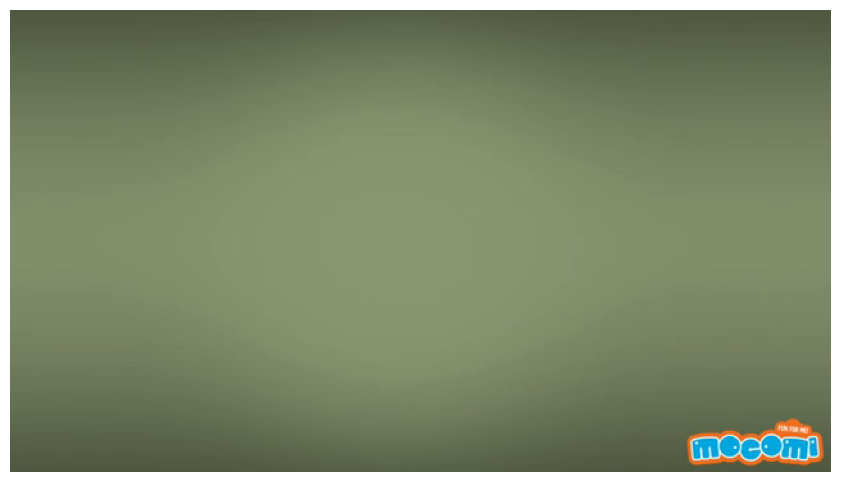

In [2]:
import cv2
import matplotlib.pyplot as plt

video_path = "data/Raw-and-Boiled-SnapYT.App.mp4"

cap = cv2.VideoCapture(video_path)

ret, frame = cap.read()

if ret:
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(12, 6))
    plt.imshow(frame_rgb)
    plt.axis("off")
    plt.show()
else:
    print("Could not read video.")

cap.release()

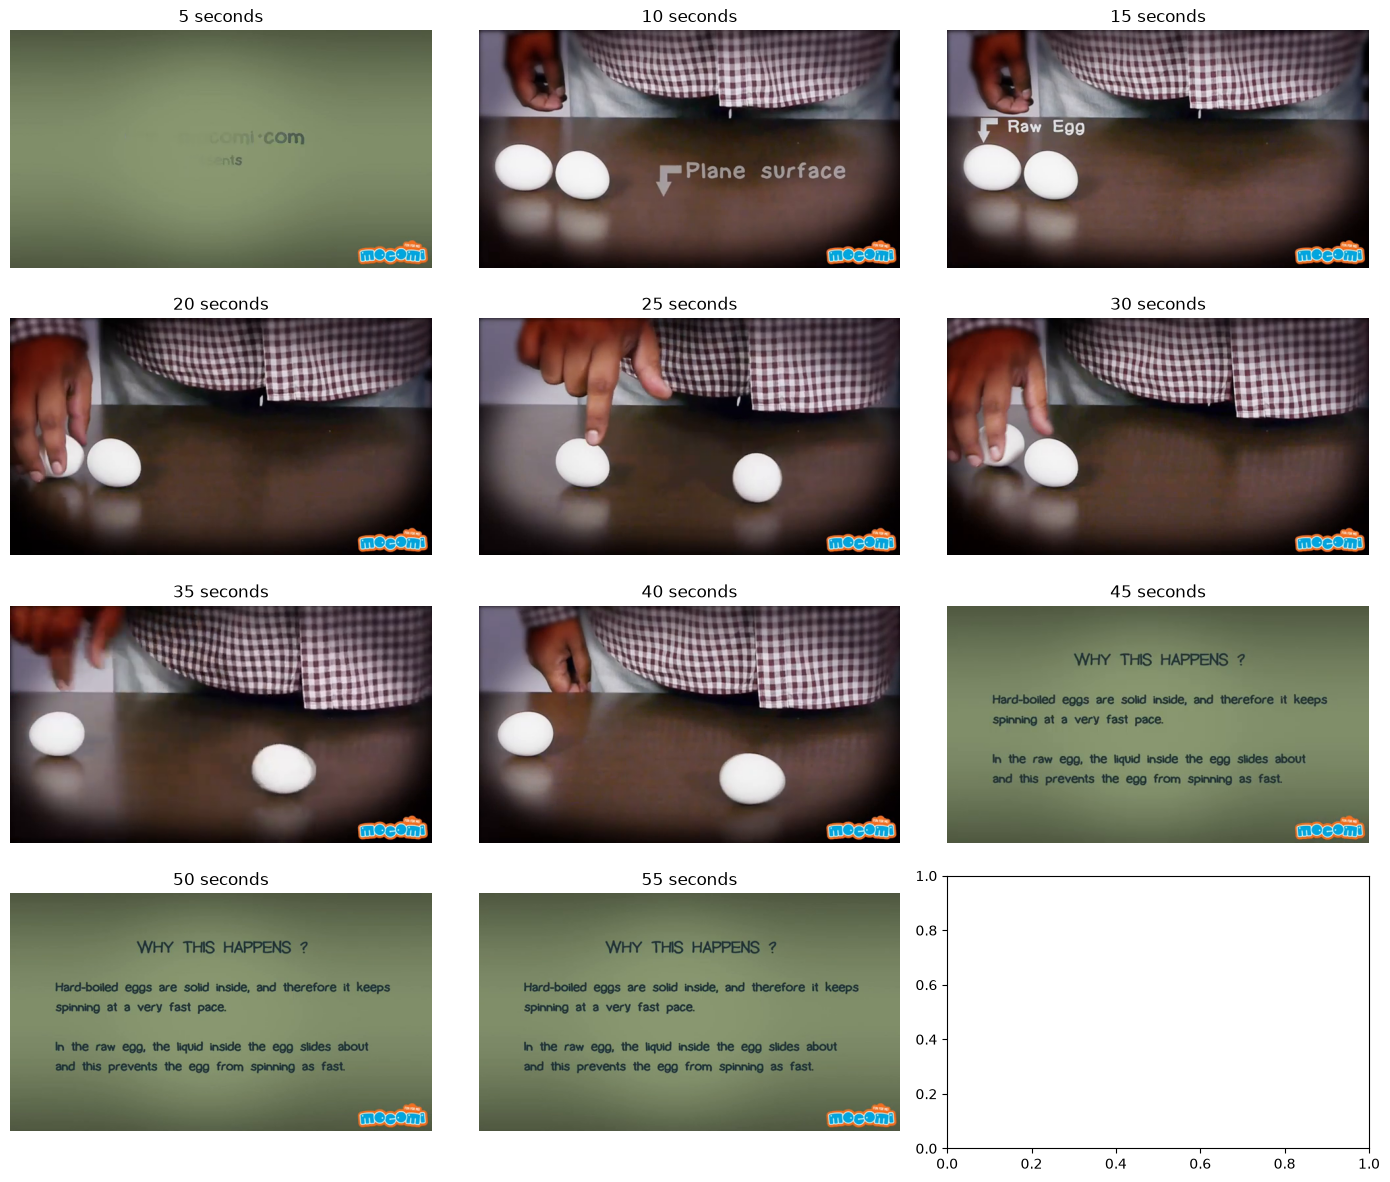

In [3]:
import cv2
import matplotlib.pyplot as plt

video_path = "/home/mohsinkhan/Egg/data/Raw-and-Boiled-SnapYT.App.mp4"

cap = cv2.VideoCapture(video_path)

timestamps = [5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55]

fig, axes = plt.subplots(4, 3, figsize=(14, 12))
axes = axes.flatten()

for ax, seconds in zip(axes, timestamps):
    cap.set(cv2.CAP_PROP_POS_MSEC, seconds * 1000)
    ret, frame = cap.read()

    if ret:
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        ax.imshow(frame)
        ax.set_title(f"{seconds} seconds")
    else:
        ax.set_title(f"{seconds} seconds — failed")

    ax.axis("off")

cap.release()
plt.tight_layout()
plt.show()

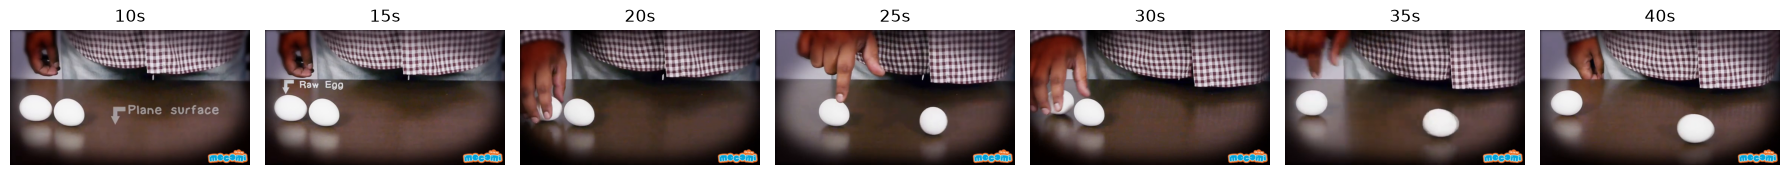

In [5]:


video_path = "/home/mohsinkhan/Egg/data/Raw-and-Boiled-SnapYT.App.mp4"
cap = cv2.VideoCapture(video_path)

timestamps = [10, 15, 20, 25, 30, 35, 40]

fig, axes = plt.subplots(1, len(timestamps), figsize=(18, 4))

for ax, seconds in zip(axes, timestamps):
    cap.set(cv2.CAP_PROP_POS_MSEC, seconds * 1000)
    ret, frame = cap.read()

    if ret:
        ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        ax.set_title(f"{seconds}s")

    ax.axis("off")

cap.release()
plt.tight_layout()
plt.show()

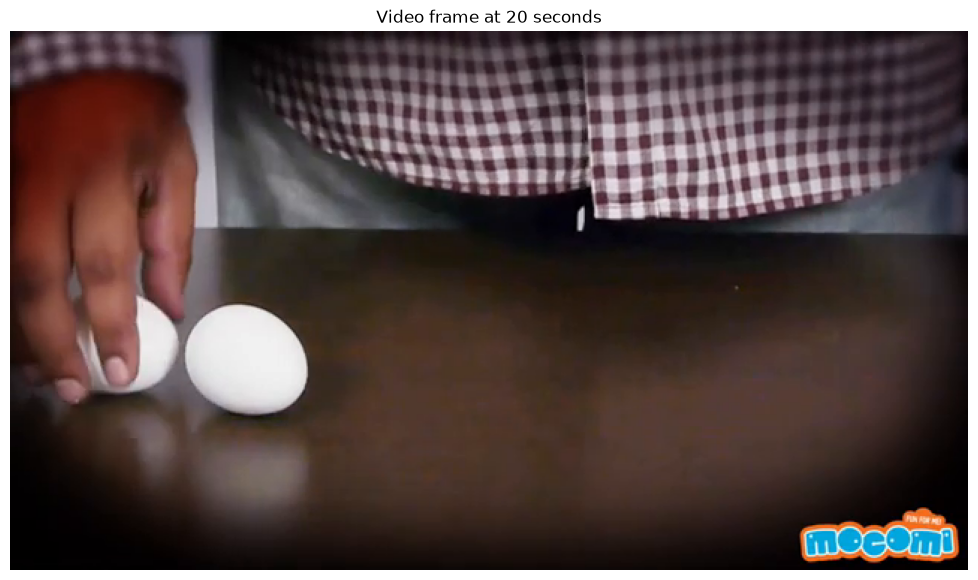

In [6]:


video_path = "/home/mohsinkhan/Egg/data/Raw-and-Boiled-SnapYT.App.mp4"

cap = cv2.VideoCapture(video_path)
cap.set(cv2.CAP_PROP_POS_MSEC, 20_000)

ret, frame = cap.read()
cap.release()

if ret:
    plt.figure(figsize=(14, 7))
    plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    plt.title("Video frame at 20 seconds")
    plt.axis("off")
    plt.show()
else:
    print("Could not read frame.")

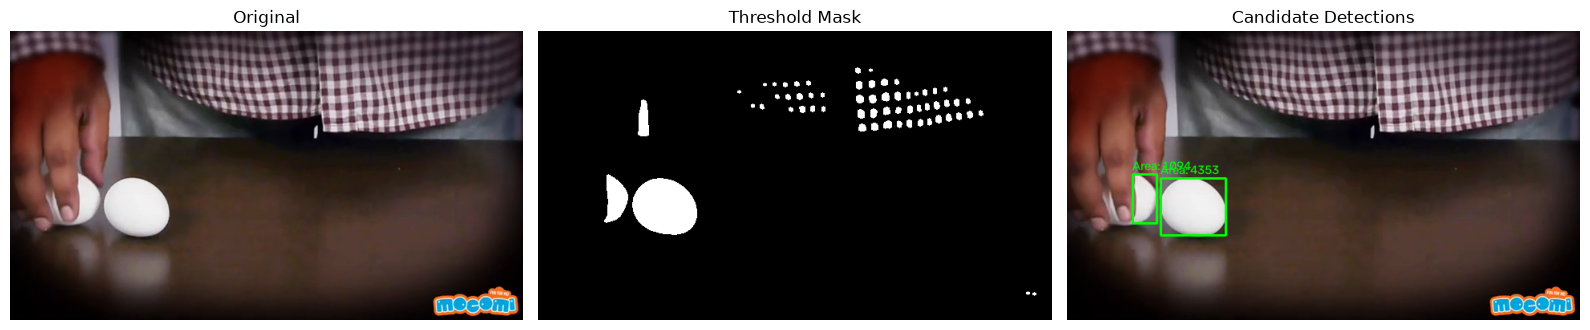

In [7]:
import numpy as np

cap = cv2.VideoCapture(video_path)
cap.set(cv2.CAP_PROP_POS_MSEC, 20_000)
ret, frame = cap.read()
cap.release()

if not ret:
    raise RuntimeError("Could not read video frame")

# Convert to grayscale and blur
gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

# White eggs should be brighter than the table
_, mask = cv2.threshold(
    blurred, 170, 255, cv2.THRESH_BINARY
)

# Remove small noise
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)

# Find candidate egg regions
contours, _ = cv2.findContours(
    mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

output = frame.copy()

for contour in contours:
    area = cv2.contourArea(contour)

    if area > 500:
        x, y, w, h = cv2.boundingRect(contour)
        cv2.rectangle(output, (x, y), (x + w, y + h), (0, 255, 0), 2)
        cv2.putText(
            output, f"Area: {int(area)}",
            (x, max(20, y - 5)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1
        )

# Display original, binary mask, and detections
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original")

axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Threshold Mask")

axes[2].imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
axes[2].set_title("Candidate Detections")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


Candidates: 1


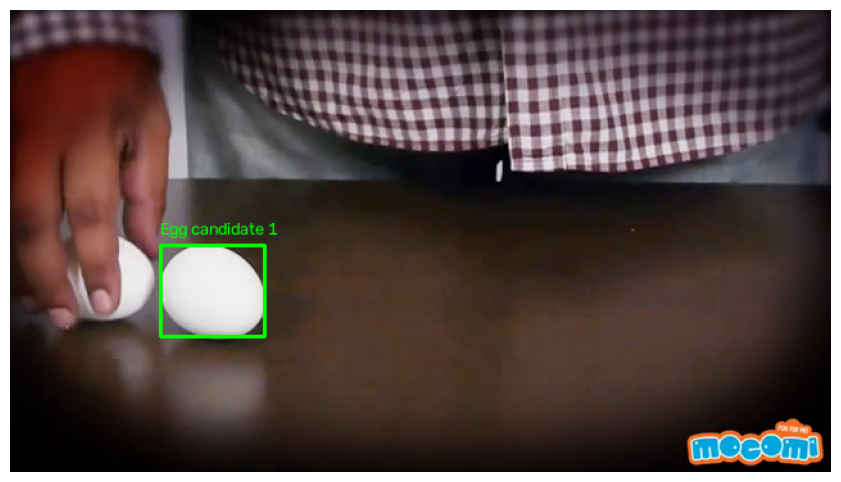

In [8]:
# Find contours from the existing threshold mask
contours, _ = cv2.findContours(
    mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

output = frame.copy()
detections = []

for contour in contours:
    area = cv2.contourArea(contour)

    if area < 800:
        continue

    x, y, w, h = cv2.boundingRect(contour)

    # Reject regions that are too small or too narrow
    aspect_ratio = w / max(h, 1)

    hull = cv2.convexHull(contour)
    hull_area = cv2.contourArea(hull)
    solidity = area / max(hull_area, 1)

    if not (0.65 <= aspect_ratio <= 1.8):
        continue

    if solidity < 0.75:
        continue

    detections.append((x, y, w, h))

    cv2.rectangle(output, (x, y), (x + w, y + h), (0, 255, 0), 2)

for i, (x, y, w, h) in enumerate(detections, start=1):
    cv2.putText(
        output, f"Egg candidate {i}",
        (x, max(20, y - 8)),
        cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 255, 0), 1
    )

print("Candidates:", len(detections))

plt.figure(figsize=(12, 6))
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()


Candidate regions: 2


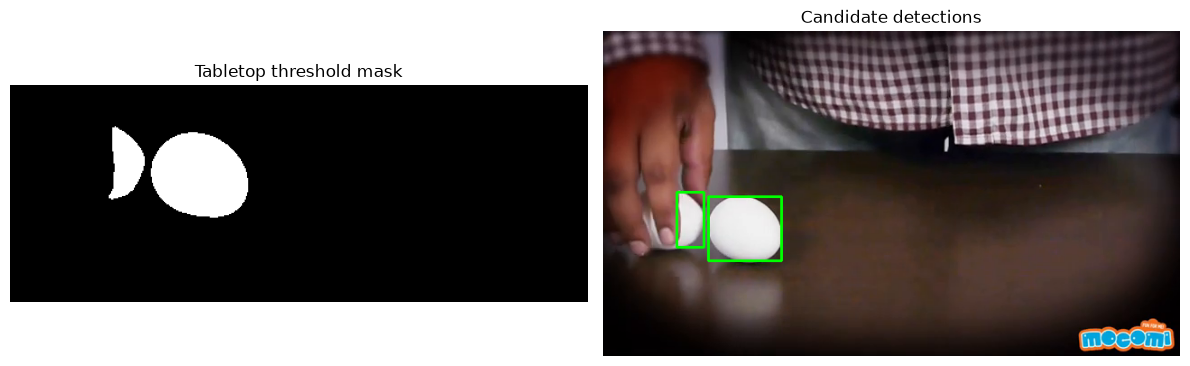

In [9]:
# Restrict detection to the tabletop
h, w = frame.shape[:2]

roi_y1, roi_y2 = int(h * 0.40), int(h * 0.90)
roi_x1, roi_x2 = int(w * 0.00), int(w * 0.75)

roi = frame[roi_y1:roi_y2, roi_x1:roi_x2]

gray_roi = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)
blurred_roi = cv2.GaussianBlur(gray_roi, (5, 5), 0)

# Threshold bright objects in the tabletop region
_, roi_mask = cv2.threshold(
    blurred_roi, 170, 255, cv2.THRESH_BINARY
)

kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (5, 5)
)
roi_mask = cv2.morphologyEx(
    roi_mask, cv2.MORPH_OPEN, kernel
)

contours, _ = cv2.findContours(
    roi_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

output = frame.copy()
detections = []

for contour in contours:
    area = cv2.contourArea(contour)

    if area < 500:
        continue

    x, y, bw, bh = cv2.boundingRect(contour)

    # Convert ROI coordinates back to full-frame coordinates
    x += roi_x1
    y += roi_y1

    detections.append((x, y, bw, bh))
    cv2.rectangle(
        output, (x, y), (x + bw, y + bh), (0, 255, 0), 2
    )

print("Candidate regions:", len(detections))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(roi_mask, cmap="gray")
axes[0].set_title("Tabletop threshold mask")
axes[1].imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
axes[1].set_title("Candidate detections")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [29]:
import numpy as np
from math import hypot

class EggTracker:
    def __init__(self, max_distance=100, max_missing=60, max_eggs=2):
        self.tracks = {}
        self.next_id = 1
        self.max_distance = max_distance
        self.max_missing = max_missing
        self.max_eggs = max_eggs

    def update(self, detections):
        # Calculate detection centroids
        centroids = [
            (x + w / 2, y + h / 2)
            for x, y, w, h in detections
        ]

        # Predict positions using recent velocity
        candidates = []

        for object_id, track in self.tracks.items():
            cx, cy = track["center"]
            vx, vy = track["velocity"]
            missing = track["missing"]

            predicted = (
                cx + vx * (missing + 1),
                cy + vy * (missing + 1)
            )

            for i, (dx, dy) in enumerate(centroids):
                distance = hypot(dx - predicted[0], dy - predicted[1])
                if distance <= self.max_distance:
                    candidates.append((distance, object_id, i))

        # Greedy one-to-one matching
        candidates.sort()
        matched_tracks = set()
        matched_detections = set()
        assignments = {}

        for distance, object_id, i in candidates:
            if object_id in matched_tracks or i in matched_detections:
                continue

            track = self.tracks[object_id]
            old_x, old_y = track["center"]
            new_x, new_y = centroids[i]

            track["velocity"] = (
                new_x - old_x,
                new_y - old_y
            )
            track["center"] = centroids[i]
            track["missing"] = 0
            track["box"] = detections[i]

            assignments[i] = object_id
            matched_tracks.add(object_id)
            matched_detections.add(i)

        # Age unmatched tracks, retaining their IDs temporarily
        for object_id in list(self.tracks):
            if object_id not in matched_tracks:
                self.tracks[object_id]["missing"] += 1

                if self.tracks[object_id]["missing"] > self.max_missing:
                    del self.tracks[object_id]

        # Register new detections only if track capacity allows
        for i, center in enumerate(centroids):
            if i in matched_detections:
                continue

            if len(self.tracks) >= self.max_eggs:
                continue

            object_id = self.next_id
            self.next_id += 1

            self.tracks[object_id] = {
                "center": center,
                "velocity": (0, 0),
                "missing": 0,
                "box": detections[i]
            }
            assignments[i] = object_id

        return [
            (assignments[i], detections[i])
            for i in range(len(detections))
            if i in assignments
        ]

In [30]:
def detect_eggs(frame):
    """Return candidate egg bounding boxes as (x, y, w, h)."""
    height, width = frame.shape[:2]

    # Restrict processing to the tabletop
    y1, y2 = int(height * 0.40), int(height * 0.90)
    x1, x2 = 0, int(width * 0.75)

    roi = frame[y1:y2, x1:x2]
    gray = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    _, mask = cv2.threshold(blurred, 170, 255, cv2.THRESH_BINARY)

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)

    contours, _ = cv2.findContours(
        mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    detections = []

    for contour in contours:
        area = cv2.contourArea(contour)
        if area < 500:
            continue

        x, y, w, h = cv2.boundingRect(contour)

        # Convert coordinates to the full frame
        detections.append((x + x1, y + y1, w, h))

    return detections


cap = cv2.VideoCapture(video_path)
tracker = EggTracker(
    max_distance=100,
    max_missing=60,
    max_eggs=2
)
# Start with a short test segment, from 10 to 40 seconds
fps = cap.get(cv2.CAP_PROP_FPS)
start_frame = int(10 * fps)
end_frame = int(40 * fps)

cap.set(cv2.CAP_PROP_POS_FRAMES, start_frame)

tracked_frames = []
frame_index = start_frame

while frame_index < end_frame:
    ret, frame = cap.read()
    if not ret:
        break

    detections = detect_eggs(frame)
    tracked_objects = tracker.update(detections)

    for object_id, (x, y, w, h) in tracked_objects:
        cv2.rectangle(
            frame, (x, y), (x + w, y + h), (0, 255, 0), 2
        )
        cv2.putText(
            frame, f"Egg {object_id}",
            (x, max(20, y - 8)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2
        )

    # Save a preview frame every second
    if frame_index % max(1, int(fps)) == 0:
        tracked_frames.append((frame_index / fps, frame.copy()))

    frame_index += 1

cap.release()

print("Preview frames collected:", len(tracked_frames))

Preview frames collected: 30


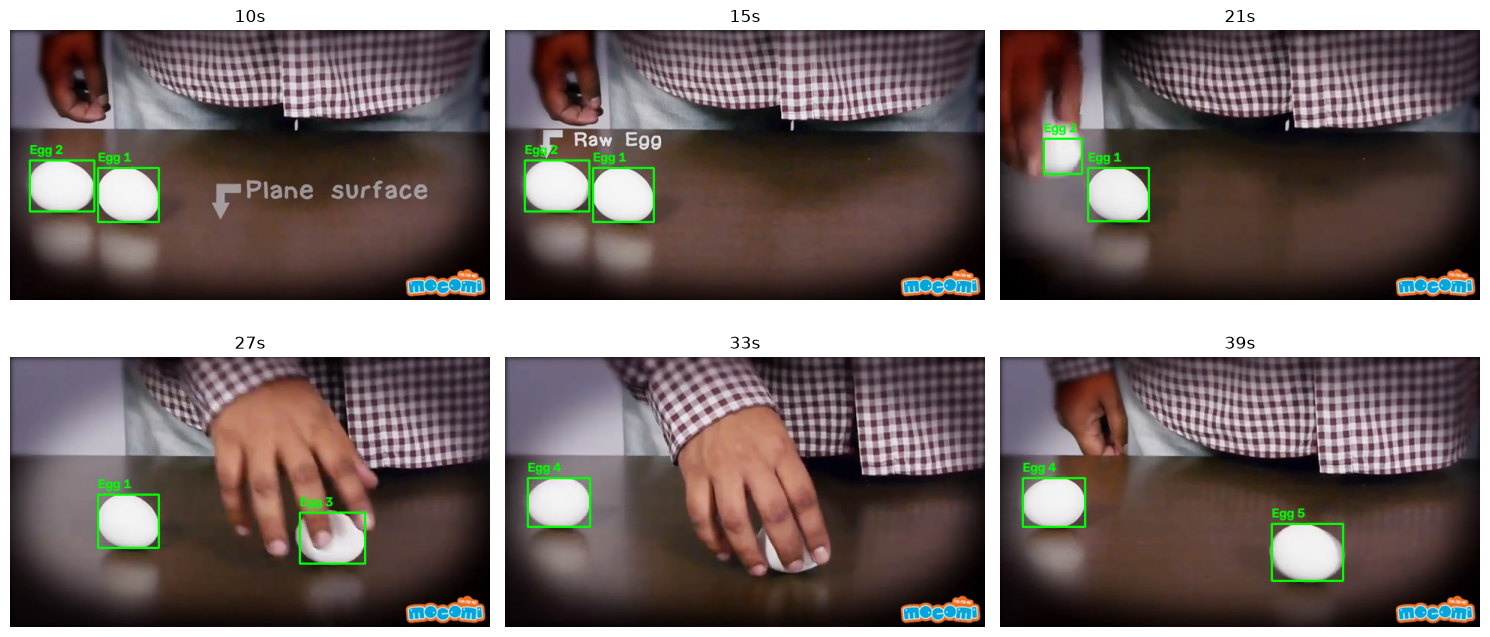

In [31]:
if tracked_frames:
    sample_indices = np.linspace(
        0, len(tracked_frames) - 1,
        min(6, len(tracked_frames)),
        dtype=int
    )

    fig, axes = plt.subplots(2, 3, figsize=(15, 7))

    for ax, index in zip(axes.flat, sample_indices):
        seconds, tracked_frame = tracked_frames[index]
        ax.imshow(cv2.cvtColor(tracked_frame, cv2.COLOR_BGR2RGB))
        ax.set_title(f"{seconds:.0f}s")
        ax.axis("off")

    for ax in axes.flat[len(sample_indices):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

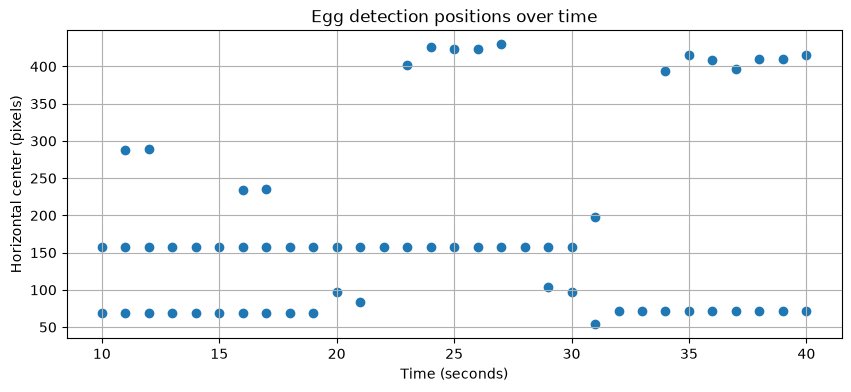

In [ ]:

times = []
centers_x = []
centers_y = []

cap = cv2.VideoCapture(video_path)
fps = cap.get(cv2.CAP_PROP_FPS)

for second in range(10, 41):
    cap.set(cv2.CAP_PROP_POS_MSEC, second * 1000)
    ret, frame = cap.read()

    if not ret:
        continue

    detections = detect_eggs(frame)

    for x, y, w, h in detections:
        times.append(second)
        centers_x.append(x + w / 2)
        centers_y.append(y + h / 2)

cap.release()

plt.figure(figsize=(10, 4))
plt.scatter(times, centers_x)
plt.xlabel("Time (seconds)")
plt.ylabel("Horizontal center (pixels)")
plt.title("Egg detection positions over time")
plt.grid(True)
plt.show()

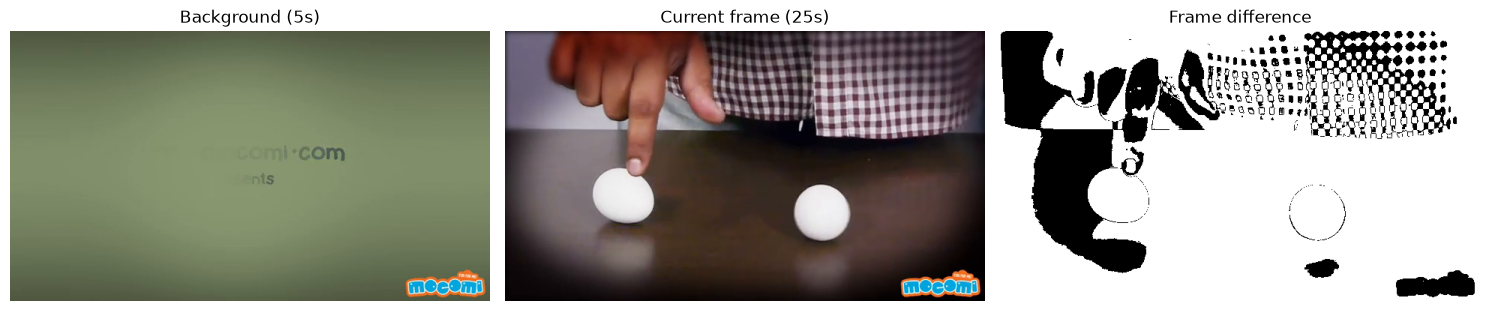

In [ ]:
import cv2
import matplotlib.pyplot as plt


cap = cv2.VideoCapture(video_path)

# Sample a frame before the eggs are present
cap.set(cv2.CAP_PROP_POS_MSEC, 5000)
ret, background = cap.read()

cap.set(cv2.CAP_PROP_POS_MSEC, 25000)
ret, current = cap.read()

cap.release()

if ret and background is not None:
    background_gray = cv2.cvtColor(background, cv2.COLOR_BGR2GRAY)
    current_gray = cv2.cvtColor(current, cv2.COLOR_BGR2GRAY)

    # Compare the two frames
    difference = cv2.absdiff(current_gray, background_gray)
    _, motion_mask = cv2.threshold(difference, 25, 255, cv2.THRESH_BINARY)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(cv2.cvtColor(background, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Background (5s)")

    axes[1].imshow(cv2.cvtColor(current, cv2.COLOR_BGR2RGB))
    axes[1].set_title("Current frame (25s)")

    axes[2].imshow(motion_mask, cmap="gray")
    axes[2].set_title("Frame difference")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Could not read the selected frames.")

In [36]:
try:
    import ultralytics
    print("Ultralytics version:", ultralytics.__version__)
except ImportError:
    print("Ultralytics is not installed")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/home/mohsinkhan/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics version: 8.4.194


In [37]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")
print(model.names)

{0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 63: 'laptop', 64: 'mouse', 65: 'remote', 66: 'keyboard', 67: 'cell phone', 68: 'microw

In [39]:
from pathlib import Path

root = Path("/home/mohsinkhan/Egg/data")

for split in ["train", "valid", "test"]:
    egg_dir = root / split / "egg"

    files = list(egg_dir.iterdir()) if egg_dir.exists() else []

    print(f"\n{split.upper()}: {len(files)} files")

    for file in files[:5]:
        print(" ", file.name)


TRAIN: 75 files
  not_damaged_100_jpg.rf.5d780a6024004fa2f68741fa56ddf4c9.jpg
  not_damaged_103_jpg.rf.c0bd961caec5acf3a6582c9cb2551634.jpg
  not_damaged_104_jpg.rf.3bf8cb51d5ad8934390c8e2c3b79b32f.jpg
  not_damaged_105_jpg.rf.6b94b57d4e4cb521abbec55bb95c2a76.jpg
  not_damaged_106_jpg.rf.4ab043b322cc9e55bdf788a4d69ae74b.jpg

VALID: 22 files
  not_damaged_102_jpg.rf.8d754cbc174c6cb6fb1b5c1929edcbb1.jpg
  not_damaged_107_jpg.rf.8497e164672ad2319ef9ea157023304e.jpg
  not_damaged_109_jpg.rf.4d74eb94b1d03ebd3e7c442e58699304.jpg
  not_damaged_115_jpg.rf.5e04f25a50022be8a5f0dbcfe42bc26f.jpg
  not_damaged_119_jpg.rf.6758625c4b939166ca105d0509fc569e.jpg

TEST: 11 files
  not_damaged_101_jpg.rf.479d12a2b41a5ec6d718dcdabd14b0c9.jpg
  not_damaged_125_jpg.rf.b19353b1f84dcbef1ec088b850927bb3.jpg
  not_damaged_14_jpg.rf.dc96559078b03433d2b65e5055904af1.jpg
  not_damaged_152_jpg.rf.a57edb18d395ce87e23f7abccbd1ad69.jpg
  not_damaged_153_jpg.rf.ea842e70f08e63e69bbcc74f1bc143a8.jpg


In [42]:

root = Path("/home/mohsinkhan/Egg")

for folder in [
    root / "outputs/egg_segmentation/combined",
    root / "outputs/egg_segmentation",
]:
    print(f"\n{folder}:")
    if folder.exists():
        for file in list(folder.iterdir())[:8]:
            print(" ", file.name)
    else:
        print(" Folder not found")


/home/mohsinkhan/Egg/outputs/egg_segmentation/combined:
  test__egg__not_damaged_101_jpg.rf.479d12a2b41a5ec6d718dcdabd14b0c9_combined.png
  test__egg__not_damaged_125_jpg.rf.b19353b1f84dcbef1ec088b850927bb3_combined.png
  test__egg__not_damaged_14_jpg.rf.dc96559078b03433d2b65e5055904af1_combined.png
  test__egg__not_damaged_152_jpg.rf.a57edb18d395ce87e23f7abccbd1ad69_combined.png
  test__egg__not_damaged_153_jpg.rf.ea842e70f08e63e69bbcc74f1bc143a8_combined.png
  test__egg__not_damaged_161_jpg.rf.fd216aa5e11e147fc1527478cceae94e_combined.png
  test__egg__not_damaged_1_jpg.rf.d74c98a14f068b48c1f58fd573361f1f_combined.png
  test__egg__not_damaged_30_jpg.rf.48e9261777355fe67139ac1c5eae596b_combined.png

/home/mohsinkhan/Egg/outputs/egg_segmentation:
  results.csv
  masks
  combined
  overlays


Image: not_damaged_100_jpg.rf.5d780a6024004fa2f68741fa56ddf4c9.jpg
Matching masks: 1
Image shape: (640, 640, 3)
Mask shape: (640, 640)
Unique mask values: [0, 255]


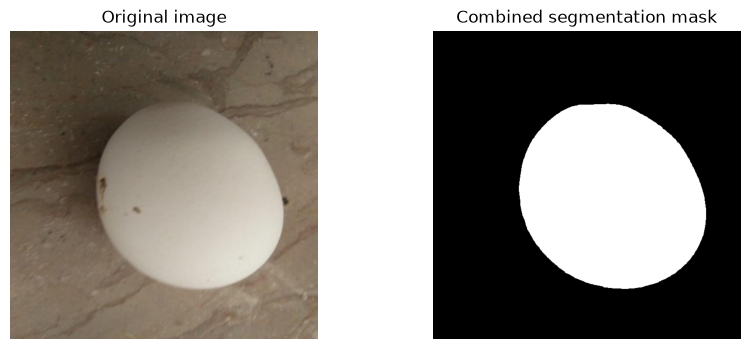

In [43]:


root = Path("/home/mohsinkhan/Egg")
image_path = next((root / "data/train/egg").glob("*.jpg"))
stem = image_path.stem

mask_dir = root / "outputs/egg_segmentation/combined"
matches = list(mask_dir.glob(f"*{stem}*_combined.png"))

print("Image:", image_path.name)
print("Matching masks:", len(matches))

if matches:
    image = cv2.cvtColor(cv2.imread(str(image_path)), cv2.COLOR_BGR2RGB)
    mask = cv2.imread(str(matches[0]), cv2.IMREAD_GRAYSCALE)

    print("Image shape:", image.shape)
    print("Mask shape:", mask.shape)
    print("Unique mask values:", sorted(set(mask.ravel().tolist()))[:20])

    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(image)
    plt.title("Original image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(mask, cmap="gray")
    plt.title("Combined segmentation mask")
    plt.axis("off")
    plt.show()
else:
    print("No matching mask found. We will check filename mapping.")

In [44]:
root = Path("/home/mohsinkhan/Egg")
mask_dir = root / "outputs/egg_segmentation/combined"

for split in ["train", "valid", "test"]:
    image_dir = root / f"data/{split}/egg"
    images = list(image_dir.glob("*.jpg"))

    matched = 0
    empty = 0
    multiple_regions = 0
    missing = []

    for image_path in images:
        prefix = f"{split}__egg__{image_path.stem}_combined.png"
        mask_path = mask_dir / prefix

        if not mask_path.exists():
            missing.append(image_path.name)
            continue

        mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
        if mask is None:
            missing.append(image_path.name)
            continue

        matched += 1
        binary = (mask > 127).astype(np.uint8)
        count, _, stats, _ = cv2.connectedComponentsWithStats(binary)

        regions = sum(
            1 for area in stats[1:, cv2.CC_STAT_AREA]
            if area > 100
        )

        if binary.sum() == 0:
            empty += 1
        if regions > 1:
            multiple_regions += 1

    print(f"\n{split.upper()}")
    print(f"Images: {len(images)} | Matched masks: {matched}")
    print(f"Empty masks: {empty} | Multiple regions: {multiple_regions}")
    print(f"Missing masks: {len(missing)}")
    if missing:
        print("Examples:", missing[:3])


TRAIN
Images: 75 | Matched masks: 75
Empty masks: 0 | Multiple regions: 20
Missing masks: 0

VALID
Images: 22 | Matched masks: 22
Empty masks: 0 | Multiple regions: 5
Missing masks: 0

TEST
Images: 11 | Matched masks: 11
Empty masks: 0 | Multiple regions: 0
Missing masks: 0


In [45]:
import shutil

root = Path("/home/mohsinkhan/Egg")
mask_dir = root / "outputs/egg_segmentation/combined"
output = root / "outputs/egg_yolo_dataset"

for split in ["train", "valid", "test"]:
    image_dir = root / f"data/{split}/egg"
    out_images = output / "images" / split
    out_labels = output / "labels" / split

    out_images.mkdir(parents=True, exist_ok=True)
    out_labels.mkdir(parents=True, exist_ok=True)

    for image_path in image_dir.glob("*.jpg"):
        mask_path = mask_dir / (
            f"{split}__egg__{image_path.stem}_combined.png"
        )

        mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
        if mask is None:
            continue

        binary = (mask > 127).astype(np.uint8)
        ys, xs = np.where(binary > 0)

        if len(xs) == 0:
            continue

        height, width = binary.shape

        # Bounding box normalized to [0, 1]
        x_center = (xs.min() + xs.max()) / 2 / width
        y_center = (ys.min() + ys.max()) / 2 / height
        box_width = (xs.max() - xs.min() + 1) / width
        box_height = (ys.max() - ys.min() + 1) / height

        label_path = out_labels / f"{image_path.stem}.txt"
        label_path.write_text(
            f"0 {x_center:.6f} {y_center:.6f} "
            f"{box_width:.6f} {box_height:.6f}\n"
        )

        shutil.copy2(image_path, out_images / image_path.name)

    print(split, "images:", len(list(out_images.glob("*.jpg"))))

# YOLO dataset configuration
(output / "data.yaml").write_text(
    f"path: {output}\n"
    "train: images/train\n"
    "val: images/valid\n"
    "test: images/test\n"
    "names:\n"
    "  0: egg\n"
)

print("\nDataset config:", output / "data.yaml")

train images: 75
valid images: 22
test images: 11

Dataset config: /home/mohsinkhan/Egg/outputs/egg_yolo_dataset/data.yaml


In [46]:
from ultralytics import YOLO
import torch

print("CUDA available:", torch.cuda.is_available())

model = YOLO("yolo11n.pt")

results = model.train(
    data="/home/mohsinkhan/Egg/outputs/egg_yolo_dataset/data.yaml",
    epochs=50,
    imgsz=640,
    batch=4,
    device=0 if torch.cuda.is_available() else "cpu",
    patience=10,
    project="/home/mohsinkhan/Egg/runs/egg_detection",
    name="yolo11n_egg",
    plots=True
)

CUDA available: True
Ultralytics 8.4.194 🚀 Python-3.14.7 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 3824MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/mohsinkhan/Egg/outputs/egg_yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale

In file included from /usr/include/python3.14/pyconfig.h:6,
                 from /usr/include/python3.14/Python.h:14,
                 from /home/mohsinkhan/Egg/venv/lib/python3.14/site-packages/triton/backends/nvidia/driver.c:9:
/usr/include/python3.14/pyconfig-64.h:2031:9: warning: ‘_POSIX_C_SOURCE’ redefined
 2031 | #define _POSIX_C_SOURCE 200809L
      |         ^~~~~~~~~~~~~~~
In file included from /usr/include/bits/libc-header-start.h:33,
                 from /usr/include/stdlib.h:26,
                 from /home/mohsinkhan/Egg/venv/lib/python3.14/site-packages/triton/backends/nvidia/include/cuda.h:56,
                 from /home/mohsinkhan/Egg/venv/lib/python3.14/site-packages/triton/backends/nvidia/driver.c:1:
/usr/include/features.h:319:10: note: this is the location of the previous definition
  319 | # define _POSIX_C_SOURCE        202405L
      |          ^~~~~~~~~~~~~~~
/home/mohsinkhan/Egg/venv/lib64/python3.14/site-packages/triton/knobs.py:504: UserWarning: TRITON_DEFAUL

YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 5.2it/s 0.6s0.3s
                   all         22         22       0.45      0.633      0.394      0.308
Speed: 3.8ms preprocess, 10.4ms inference, 0.0ms loss, 5.8ms postprocess per image
Results saved to /home/mohsinkhan/Egg/runs/egg_detection/yolo11n_egg


In [47]:
from ultralytics import YOLO

model = YOLO(
    "/home/mohsinkhan/Egg/runs/egg_detection/yolo11n_egg/weights/best.pt"
)

video_path = "/home/mohsinkhan/Egg/data/Raw-and-Boiled-SnapYT.App.mp4"

results = model.predict(
    source=video_path,
    conf=0.25,
    imgsz=640,
    save=True,
    project="/home/mohsinkhan/Egg/runs/video_detection",
    name="egg_detector"
)

print("Video inference complete.")
print("Output saved under:")
print("/home/mohsinkhan/Egg/runs/video_detection/egg_detector")


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/1440) /home/mohsinkhan/Egg/data/Raw-and-Boiled-SnapYT.App.mp4: 384x640 (no detections), 11.9ms
video 1/1 (frame 2/1440) /home/mohsinkhan/Egg/data/Raw-and-Boiled-SnapYT.App.mp4: 384x640 (no detections), 13.1ms
video 1/1 (frame 3/1440) /home/mohsinkhan/Egg/data/Raw-and-Boiled-SnapYT.App.mp4: 384x640 (no detections), 11.5ms
video 1/1 (frame 4/1440) /home/mohsinkhan/Egg/data/Raw-and-Boiled-SnapYT.App.mp4: 384x640 (no detections), 13.5ms
vid

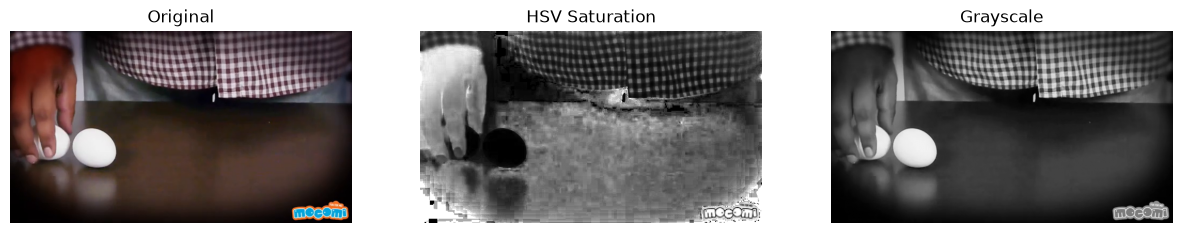

In [2]:
import cv2
import matplotlib.pyplot as plt
video_path = "/home/mohsinkhan/Egg/data/Raw-and-Boiled-SnapYT.App.mp4"

cap = cv2.VideoCapture(video_path)

# Read a frame at 20 seconds
cap.set(cv2.CAP_PROP_POS_MSEC, 20000)
success, frame = cap.read()
cap.release()

if success:
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(hsv[:, :, 1], cmap="gray")
    plt.title("HSV Saturation")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(gray, cmap="gray")
    plt.title("Grayscale")
    plt.axis("off")

    plt.show()
else:
    print("Could not read the video frame.")

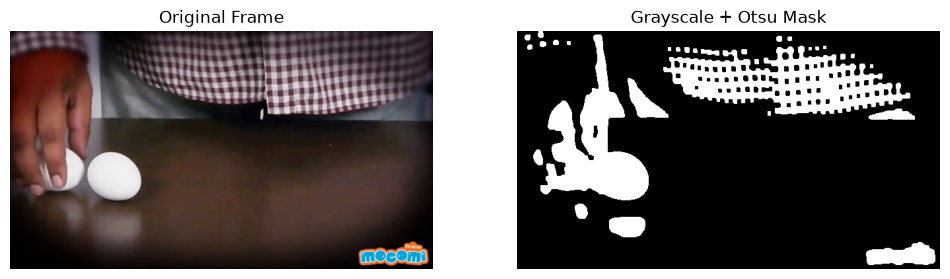

Otsu threshold: 93.0


In [4]:
import numpy as np
# Convert to grayscale
gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

# Blur to reduce small texture variations
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

# Otsu thresholding
_, mask = cv2.threshold(
    blurred, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Remove small noise and smooth regions
kernel = np.ones((5, 5), np.uint8)
mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

# Display original and mask
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.title("Original Frame")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap="gray")
plt.title("Grayscale + Otsu Mask")
plt.axis("off")

plt.show()
print("Otsu threshold:", _)

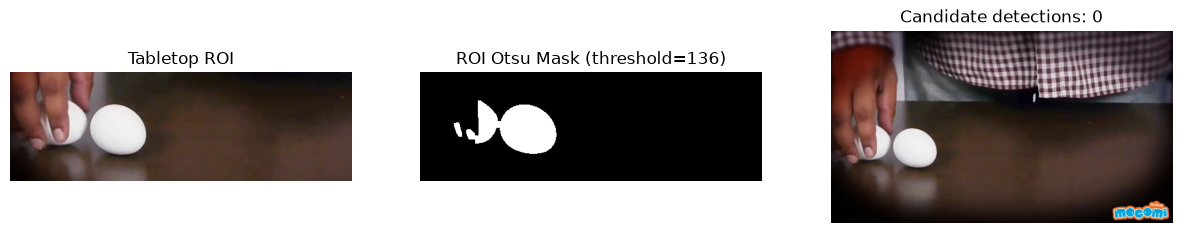

In [5]:
height, width = frame.shape[:2]

# Restrict processing to the tabletop
roi = frame[int(height * 0.38):int(height * 0.82),
            int(width * 0.0):int(width * 0.78)]

gray_roi = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)
blurred_roi = cv2.GaussianBlur(gray_roi, (7, 7), 0)

# Otsu thresholding
threshold_value, mask_roi = cv2.threshold(
    blurred_roi, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Smooth the mask
kernel = np.ones((5, 5), np.uint8)
mask_roi = cv2.morphologyEx(mask_roi, cv2.MORPH_OPEN, kernel)
mask_roi = cv2.morphologyEx(mask_roi, cv2.MORPH_CLOSE, kernel)

# Find candidate egg contours
contours, _ = cv2.findContours(
    mask_roi, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

annotated = frame.copy()
candidates = []

for contour in contours:
    area = cv2.contourArea(contour)
    x, y, w, h = cv2.boundingRect(contour)

    if area < 400 or w < 15 or h < 15:
        continue

    # Approximate egg-like shape
    aspect_ratio = w / h
    if 0.55 <= aspect_ratio <= 1.6:
        candidates.append((area, x, y, w, h))

y_offset = int(height * 0.38)

for egg_id, (area, x, y, w, h) in enumerate(
    sorted(candidates, reverse=True)[:5], start=1
):
    cv2.rectangle(
        annotated, (x, y + y_offset),
        (x + w, y + h + y_offset), (0, 255, 0), 2
    )
    cv2.putText(
        annotated, f"Candidate {egg_id}",
        (x, y + y_offset - 8),
        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2
    )

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(roi, cv2.COLOR_BGR2RGB))
plt.title("Tabletop ROI")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask_roi, cmap="gray")
plt.title(f"ROI Otsu Mask (threshold={threshold_value:.0f})")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.title(f"Candidate detections: {len(candidates)}")
plt.axis("off")

plt.show()

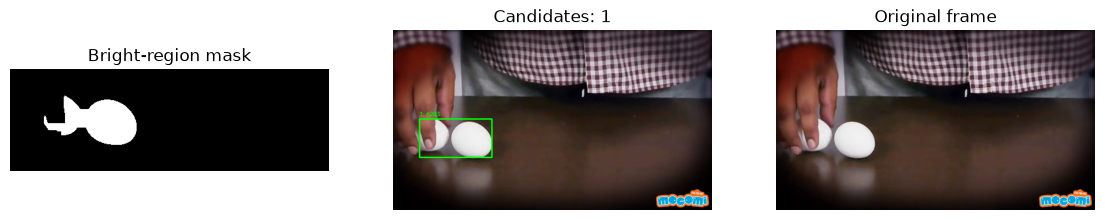

In [6]:
# Use the existing ROI and blurred_roi variables

# Threshold bright regions with a lower fixed threshold
_, bright_mask = cv2.threshold(blurred_roi, 155, 255, cv2.THRESH_BINARY)

# Close small gaps, especially around the partially occluded egg
kernel = np.ones((7, 7), np.uint8)
bright_mask = cv2.morphologyEx(
    bright_mask, cv2.MORPH_CLOSE, kernel, iterations=2
)

contours, _ = cv2.findContours(
    bright_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

annotated = frame.copy()
y_offset = int(frame.shape[0] * 0.38)
candidates = []

for contour in contours:
    area = cv2.contourArea(contour)
    x, y, w, h = cv2.boundingRect(contour)

    if area >= 100:
        candidates.append((area, x, y, w, h))

for i, (area, x, y, w, h) in enumerate(
    sorted(candidates, reverse=True)[:10], start=1
):
    cv2.rectangle(
        annotated, (x, y + y_offset),
        (x + w, y + h + y_offset), (0, 255, 0), 2
    )
    cv2.putText(
        annotated, f"{i}: {int(area)}",
        (x, y + y_offset - 5),
        cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 255, 0), 1
    )

plt.figure(figsize=(14, 5))
plt.subplot(1, 3, 1)
plt.imshow(bright_mask, cmap="gray")
plt.title("Bright-region mask")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.title(f"Candidates: {len(candidates)}")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.title("Original frame")
plt.axis("off")
plt.show()

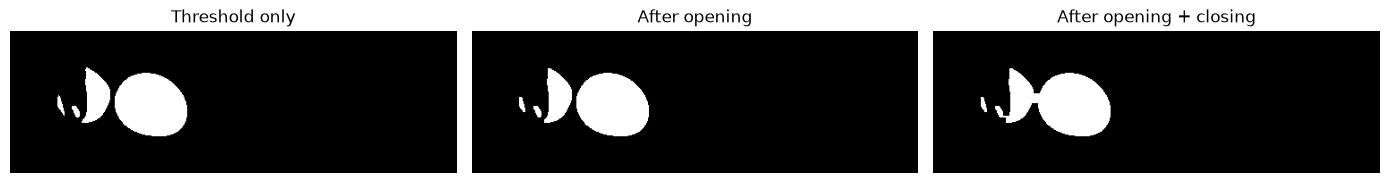

Threshold only: 2 candidate contours
After opening: 2 candidate contours
After opening + closing: 1 candidate contours


In [7]:
# Use the existing bright_mask and roi variables

# Compare masks with different morphological operations
kernel_small = np.ones((3, 3), np.uint8)
kernel_large = np.ones((7, 7), np.uint8)

mask_original = cv2.threshold(
    blurred_roi, 155, 255, cv2.THRESH_BINARY
)[1]

mask_opened = cv2.morphologyEx(
    mask_original, cv2.MORPH_OPEN, kernel_small
)

mask_closed = cv2.morphologyEx(
    mask_opened, cv2.MORPH_CLOSE, kernel_large
)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].imshow(mask_original, cmap="gray")
axes[0].set_title("Threshold only")

axes[1].imshow(mask_opened, cmap="gray")
axes[1].set_title("After opening")

axes[2].imshow(mask_closed, cmap="gray")
axes[2].set_title("After opening + closing")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

for name, test_mask in [
    ("Threshold only", mask_original),
    ("After opening", mask_opened),
    ("After opening + closing", mask_closed),
]:
    contours, _ = cv2.findContours(
        test_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    valid = [c for c in contours if cv2.contourArea(c) >= 100]
    print(f"{name}: {len(valid)} candidate contours")

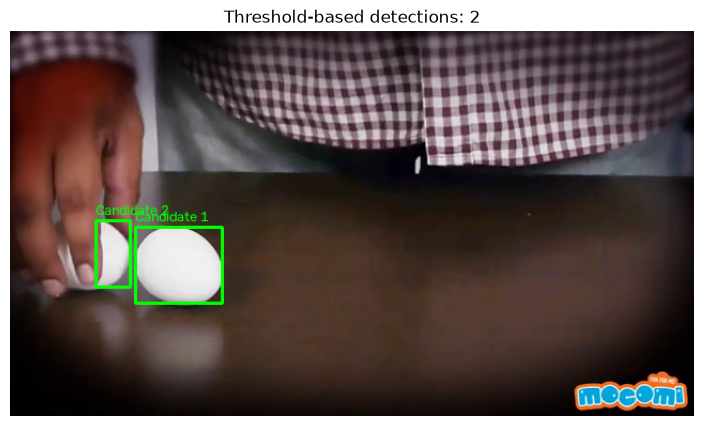

{'area': 4424.0, 'box': (117, 47, 81, 71)}
{'area': 1163.5, 'box': (80, 41, 32, 62)}


In [8]:
# Use the existing mask_original, roi, and frame variables

contours, _ = cv2.findContours(
    mask_original, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

annotated = frame.copy()
y_offset = int(frame.shape[0] * 0.38)
detections = []

for contour in contours:
    area = cv2.contourArea(contour)
    x, y, w, h = cv2.boundingRect(contour)

    if area < 100:
        continue

    detections.append({
        "area": area,
        "box": (x, y, w, h)
    })

# Draw all candidate regions
for i, detection in enumerate(
    sorted(detections, key=lambda d: d["area"], reverse=True), start=1
):
    x, y, w, h = detection["box"]

    cv2.rectangle(
        annotated,
        (x, y + y_offset),
        (x + w, y + h + y_offset),
        (0, 255, 0), 2
    )

    cv2.putText(
        annotated, f"Candidate {i}",
        (x, y + y_offset - 5),
        cv2.FONT_HERSHEY_SIMPLEX, 0.45,
        (0, 255, 0), 1
    )

plt.figure(figsize=(12, 5))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.title(f"Threshold-based detections: {len(detections)}")
plt.axis("off")
plt.show()

for detection in detections:
    print(detection)

In [10]:
# Persistent tracking state
next_egg_id = 1
tracked_eggs = {}  # ID -> previous center (cx, cy)
max_distance = 60  # pixels

In [13]:
video_path = "/home/mohsinkhan/Egg/data/Raw-and-Boiled-SnapYT.App.mp4"
output_path = "/home/mohsinkhan/Egg/outputs/egg_tracking_classical.avi"

cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise RuntimeError("Cannot open input video")

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

writer = cv2.VideoWriter(
    output_path,
    cv2.VideoWriter_fourcc(*"MJPG"),
    fps,
    (width, height)
)

# Exactly two persistent IDs
tracks = {
    1: {"center": None, "missing": 0},
    2: {"center": None, "missing": 0}
}

MAX_DISTANCE = 70
MAX_MISSING = 12

while True:
    success, current_frame = cap.read()
    if not success:
        break

    h, w = current_frame.shape[:2]

    # Tabletop ROI
    y1, y2 = int(h * 0.38), int(h * 0.82)
    x1, x2 = 0, int(w * 0.78)
    roi = current_frame[y1:y2, x1:x2]

    # Grayscale + thresholding
    gray = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (7, 7), 0)

    _, mask = cv2.threshold(
        blurred, 155, 255, cv2.THRESH_BINARY
    )

    contours, _ = cv2.findContours(
        mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    candidates = []

    for contour in contours:
        area = cv2.contourArea(contour)
        if area < 100:
            continue

        x, y, bw, bh = cv2.boundingRect(contour)

        candidates.append({
            "box": (x + x1, y + y1, bw, bh),
            "center": (
                x + x1 + bw // 2,
                y + y1 + bh // 2
            ),
            "area": area
        })

    # Keep only the two largest candidate regions
    candidates.sort(key=lambda d: d["area"], reverse=True)
    detections = candidates[:2]

    # Find the best one-to-one match between two tracks and detections
    best_assignment = {}
    best_cost = float("inf")

    if len(detections) == 2:
        # Test both possible pairings
        for pairing in [(0, 1), (1, 0)]:
            cost = 0
            valid = True

            for egg_id, det_idx in zip([1, 2], pairing):
                previous = tracks[egg_id]["center"]
                current = detections[det_idx]["center"]

                if previous is not None:
                    distance = np.hypot(
                        current[0] - previous[0],
                        current[1] - previous[1]
                    )
                    cost += distance

                    if distance > MAX_DISTANCE:
                        valid = False

            if valid and cost < best_cost:
                best_cost = cost
                best_assignment = {1: pairing[0], 2: pairing[1]}

    elif len(detections) == 1:
        # Match one detection to the closest existing track
        det_center = detections[0]["center"]
        distances = {}

        for egg_id in [1, 2]:
            previous = tracks[egg_id]["center"]

            distances[egg_id] = (
                np.hypot(
                    det_center[0] - previous[0],
                    det_center[1] - previous[1]
                )
                if previous is not None else float("inf")
            )

        closest_id = min(distances, key=distances.get)

        if distances[closest_id] <= MAX_DISTANCE or distances[closest_id] == float("inf"):
            best_assignment = {closest_id: 0}

    # Update positions; retain old centers during missing detections
    matched_ids = set()

    for egg_id, det_idx in best_assignment.items():
        det = detections[det_idx]
        tracks[egg_id]["center"] = det["center"]
        tracks[egg_id]["missing"] = 0
        matched_ids.add(egg_id)

    for egg_id in [1, 2]:
        if egg_id not in matched_ids:
            tracks[egg_id]["missing"] += 1

            if tracks[egg_id]["missing"] > MAX_MISSING:
                tracks[egg_id]["center"] = None

    # Draw annotations using only IDs 1 and 2
    for egg_id, det_idx in best_assignment.items():
        x, y, bw, bh = detections[det_idx]["box"]

        cv2.rectangle(
            current_frame,
            (x, y),
            (x + bw, y + bh),
            (0, 255, 0),
            2
        )

        cv2.putText(
            current_frame,
            f"Egg {egg_id}",
            (x, max(20, y - 8)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.55,
            (0, 255, 0),
            2
        )

    writer.write(current_frame)

cap.release()
writer.release()

print("Saved:", output_path)
print("Only Egg 1 and Egg 2 can be assigned.")

Saved: /home/mohsinkhan/Egg/outputs/egg_tracking_classical.avi
Only Egg 1 and Egg 2 can be assigned.


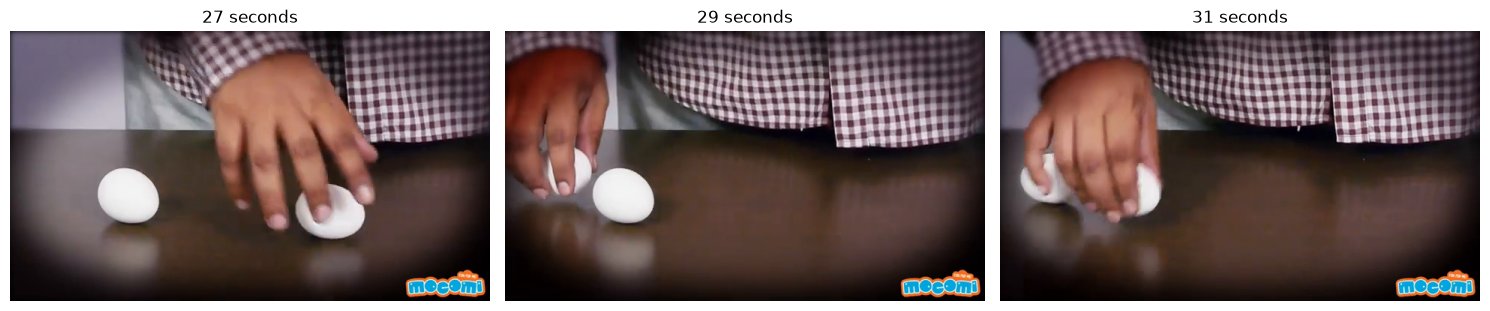

In [14]:
video_path = "/home/mohsinkhan/Egg/data/Raw-and-Boiled-SnapYT.App.mp4"

cap = cv2.VideoCapture(video_path)

timestamps = [27, 29, 31]
frames = []

for seconds in timestamps:
    cap.set(cv2.CAP_PROP_POS_MSEC, seconds * 1000)
    success, sample = cap.read()

    if success:
        frames.append((seconds, sample))

cap.release()

fig, axes = plt.subplots(1, len(frames), figsize=(15, 5))

for ax, (seconds, sample) in zip(axes, frames):
    ax.imshow(cv2.cvtColor(sample, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{seconds} seconds")
    ax.axis("off")

plt.tight_layout()
plt.show()

Contour areas: [4485.5, 884.5, 417.5, 224.0, 121.5, 12.5]


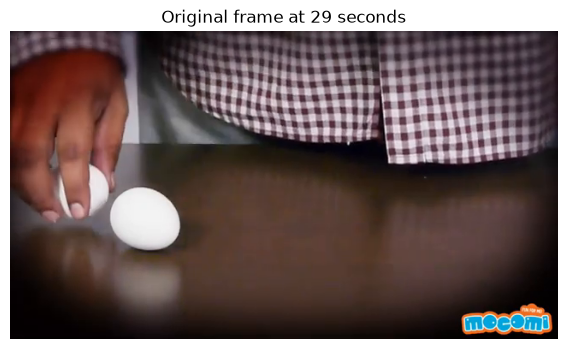

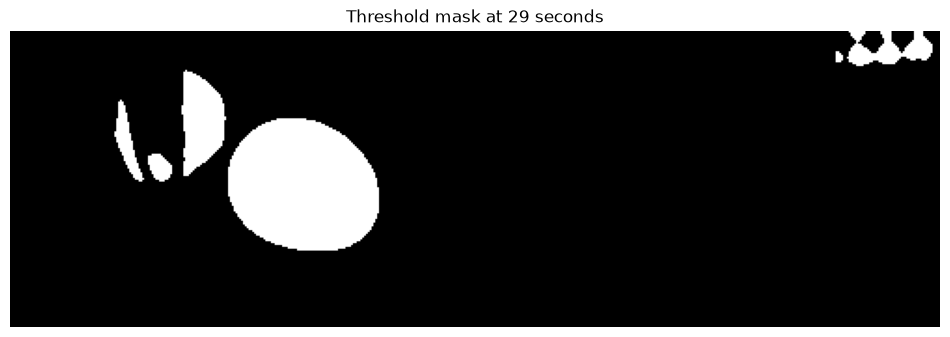

In [15]:
video_path = "/home/mohsinkhan/Egg/data/Raw-and-Boiled-SnapYT.App.mp4"

cap = cv2.VideoCapture(video_path)
cap.set(cv2.CAP_PROP_POS_MSEC, 29_000)
success, frame = cap.read()
cap.release()

if success:
    height, width = frame.shape[:2]
    y1, y2 = int(height * 0.38), int(height * 0.82)
    x1, x2 = 0, int(width * 0.78)

    roi = frame[y1:y2, x1:x2]
    gray = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)
    blurred_roi = cv2.GaussianBlur(gray, (7, 7), 0)
    mask_original = cv2.threshold(
        blurred_roi, 155, 255, cv2.THRESH_BINARY
    )[1]

    contours, _ = cv2.findContours(
        mask_original, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    print("Contour areas:", sorted(
        [round(cv2.contourArea(c), 1) for c in contours],
        reverse=True
    )[:15])

    plt.figure(figsize=(12, 4))
    plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    plt.title("Original frame at 29 seconds")
    plt.axis("off")
    plt.show()

    plt.figure(figsize=(12, 4))
    plt.imshow(mask_original, cmap="gray")
    plt.title("Threshold mask at 29 seconds")
    plt.axis("off")
    plt.show()

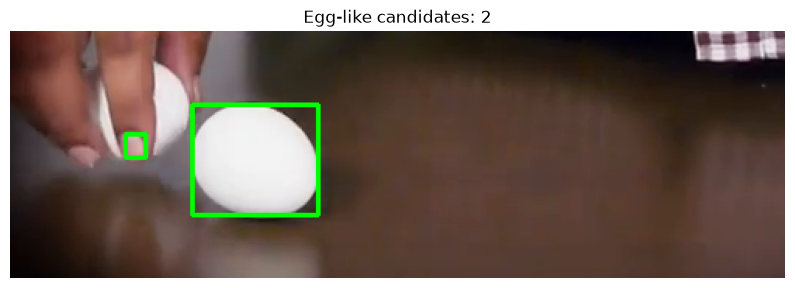

In [16]:
egg_candidates = []

for contour in contours:
    area = cv2.contourArea(contour)

    if area < 100:
        continue

    x, y, w, h = cv2.boundingRect(contour)
    aspect_ratio = w / max(h, 1)
    extent = area / max(w * h, 1)

    # Broad filters; tune after viewing the results
    if 0.5 <= aspect_ratio <= 1.8 and extent > 0.45:
        egg_candidates.append(contour)

debug_frame = roi.copy()

for contour in egg_candidates:
    x, y, w, h = cv2.boundingRect(contour)
    cv2.rectangle(debug_frame, (x, y), (x + w, y + h), (0, 255, 0), 2)

plt.figure(figsize=(10, 5))
plt.imshow(cv2.cvtColor(debug_frame, cv2.COLOR_BGR2RGB))
plt.title(f"Egg-like candidates: {len(egg_candidates)}")
plt.axis("off")
plt.show()

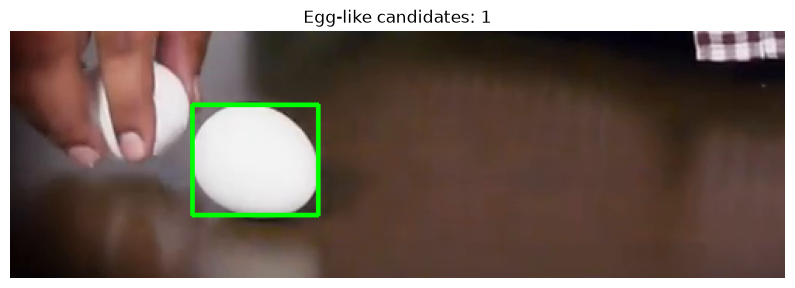

In [17]:
egg_candidates = []

for contour in contours:
    area = cv2.contourArea(contour)

    if area < 1500:
        continue

    x, y, w, h = cv2.boundingRect(contour)
    aspect_ratio = w / max(h, 1)
    extent = area / max(w * h, 1)

    if 0.65 <= aspect_ratio <= 1.6 and extent > 0.5:
        egg_candidates.append(contour)

debug_frame = roi.copy()

for contour in egg_candidates:
    x, y, w, h = cv2.boundingRect(contour)
    cv2.rectangle(debug_frame, (x, y), (x + w, y + h), (0, 255, 0), 2)

plt.figure(figsize=(10, 5))
plt.imshow(cv2.cvtColor(debug_frame, cv2.COLOR_BGR2RGB))
plt.title(f"Egg-like candidates: {len(egg_candidates)}")
plt.axis("off")
plt.show()